<a href="https://colab.research.google.com/github/hamzafarooq/multi-agent-course/blob/main/FDE-03-assignments/ReAct_vs_Router_2_ADK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ReAct vs Router, Notebook 2: with ADK 2.0**

Two ways to let an LLM use tools:

- **Router**: the model makes **one** decision: which **branch** should handle this question? That branch runs **once**, and the model writes the answer.
- **ReAct** (Reason + Act): the model works in a **loop**. It thinks, calls a tool, reads the result, and decides what to do next, until it has enough to answer.

```
               ROUTER                                      ReAct

              question                                    question
                 |                                           |
                 v                                           v
        LLM picks ONE branch                       LLM: Thought + Action  <------+
        /        |         \                                 |                   |
       v         v          v                                v                   |
 search_web  search_docs  calculator               tool runs: Observation -------+
       \         |         /                                 |     (repeat until done)
        v        v        v                                  v
       LLM writes the answer                            Final Answer

 Only the chosen branch runs, once.                Any tool, as many times as needed.
```

This notebook builds both with Google's **Agent Development Kit (ADK) 2.0**. It runs on an OpenAI model and uses SerpApi for web search.

**What you will do**

| Section | What happens |
|---|---|
| 1.1 | Write three tools as plain Python functions: web search, a company-docs lookup and a calculator |
| 1.2 | Meet the three ADK pieces you need |
| 1.3 | ReAct: one `Agent` with all three tools |
| 1.4 | Router: a `Workflow` graph that sends each question down one branch |
| 1.5 | **Exercise:** add your own tool |
| 1.6 | **Eval:** score the Router and the ReAct agent on the same 12 questions |
| 1.7 | See what ADK did for you |

**About the outputs.** Model answers and live search results change from run to run, so your wording and numbers will differ a little.

# **Setup**

### Add your keys

Add your keys in Colab's **Secrets** panel (the key icon in the left sidebar) and switch on **Notebook access** for each one.

| Secret name | Needed for | Where to get it |
|---|---|---|
| `OPENAI_API_KEY` | The model | [platform.openai.com](https://platform.openai.com) |
| `SERP_API_KEY` | The web search tool | [serpapi.com](https://serpapi.com) |

Running locally instead of Colab? Set the same names as environment variables.

### Install the packages

ADK, plus LiteLLM, which lets ADK talk to OpenAI models, and `mcp`, a package LiteLLM needs in order to load.

If Colab shows a **Restart session** button after this cell, click it once and carry on from the next cell.

In [1]:
!pip install -q --no-warn-conflicts "google-adk==2.14.0" "litellm>=1.84,<1.106.3" mcp arize-phoenix-otel openinference-instrumentation-google-adk

### Load the keys

This cell reads the two keys and stops with a clear message if one is missing.

In [3]:
import os

def get_key(name):
    """Read a key from Colab Secrets, or from an environment variable when running locally."""
    try:
        from google.colab import userdata  # only exists on Colab
        return userdata.get(name)
    except Exception:  # not on Colab, or the secret is not set
        return os.environ.get(name)

# Load the two keys. A missing key comes back as None.
OPENAI_API_KEY = get_key("OPENAI_API_KEY")
SERP_API_KEY = get_key("SERP_API_KEY")

# Stop here with a clear message if a key is missing.
assert OPENAI_API_KEY, "Add OPENAI_API_KEY (see the table above)."
assert SERP_API_KEY, "Add SERP_API_KEY (see the table above)."
print("Keys loaded.")

Keys loaded.


### Turn on tracing with Phoenix

[Arize Phoenix](https://arize.com/docs/phoenix) records every model call and tool call as a **trace**, so you can open any answer and see the steps that produced it. It runs next to this notebook: no account, no key.

- Phoenix needs different versions of some packages than ADK does, so it gets its own small Python environment. The first run of this cell takes about a minute.
- `register(auto_instrument=True)` records every ADK agent, model call and tool call from here on. Nothing else in the code changes.

In [ ]:
# Phoenix in its own Python environment, so its packages can't clash with ADK's.
!pip install -q uv
!uv venv -q phoenix-env && uv pip install -q -p phoenix-env arize-phoenix

import subprocess, time, requests
from phoenix.otel import register

# Start Phoenix and wait until it answers (up to a minute).
phoenix_server = subprocess.Popen(["phoenix-env/bin/phoenix", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(60):
    try:
        requests.get("http://localhost:6006", timeout=1)
        break
    except requests.exceptions.RequestException:
        time.sleep(1)

# Send every ADK step to it.
tracer = register(project_name="router-vs-react-adk", endpoint="http://localhost:6006/v1/traces",
                  auto_instrument=True, verbose=False).get_tracer(__name__)

def show_phoenix():
    """Show Phoenix inside this notebook on Colab, or print its link when running locally."""
    try:
        from google.colab import output  # only exists on Colab
        output.serve_kernel_port_as_iframe(6006, height=900)
    except ImportError:
        print("Open Phoenix: http://localhost:6006")

print("Phoenix is recording.")

### A helper for printing

`show()` prints a title bar above an output, so you can always see which call produced which result.

In [4]:
def show(title, body=None):
    """Print a title bar, then the body, so every output says what produced it."""
    print(f"\n{'=' * 80}\n {title}\n{'=' * 80}")
    if body is not None:
        print(body)

# **Router and ReAct with ADK 2.0**

## **1.1 Tools**

A tool is a plain Python function with **type hints and a docstring**.

ADK reads the function's name, its type hints and its docstring, and describes the tool to the model for you. The docstring matters most: it is what the model reads to decide **when** to use the tool, so write it for the model.

### Tool 1: `search_docs`

A tiny stand-in for RAG: four short documents from a made-up company, Acme. The model has never seen these, so it cannot answer from memory.

In [5]:
import re

# The whole knowledge base: four short documents, title -> text.
DOCS = {
    "Travel policy": "Employees may spend up to 180 US dollars per night on hotels and 60 US dollars per day on meals. Flights are booked in economy class.",
    "Remote work policy": "Employees may work remotely up to 3 days per week. Core hours are 10:00 to 15:00 in the employee's local time zone.",
    "Laptop policy": "Laptops are replaced every 4 years. The laptop budget is 2,000 US dollars per employee.",
    "Vacation policy": "Employees get 25 paid vacation days per year. Up to 5 unused days carry over to the next year.",
}

def search_docs(query: str) -> str:
    """Search the Acme company handbook (travel, remote work, laptop and vacation policies)."""

    # shortcut: keyword overlap, fine for 4 documents. Use embeddings (real RAG) for a real corpus.

    # 1. Keep the query's words that have 4 or more letters.
    words = set(re.findall(r"[a-z]{4,}", query.lower()))

    # 2. Score a document by how many of those words it contains.
    score = lambda title: sum(word in (title + " " + DOCS[title]).lower() for word in words)

    # 3. Take the best one. If nothing matched at all, say so.
    best = max(DOCS, key=score)
    return f"{best}: {DOCS[best]}" if score(best) else "No matching document."

### Tool 2: `search_web`

A live Google search through SerpApi. It returns Google's direct answer (if there is one) and the top three result snippets.

In [6]:
import requests

def search_web(query: str) -> str:
    """Search the live internet (Google) for current or external information."""

    # 1. Ask SerpApi to run a Google search.
    try:
        response = requests.get("https://serpapi.com/search.json", timeout=30,
                                params={"q": query, "api_key": SERP_API_KEY, "engine": "google", "num": 3})
        response.raise_for_status()  # a bad key or an empty quota counts as a failure
    except requests.exceptions.RequestException as error:
        # Return the error's name only: the full message can contain the API key.
        return f"Search error: {type(error).__name__}"
    data = response.json()

    # 2. Google's direct answer, when it shows one (an exchange rate, for example).
    box = data.get("answer_box", {})
    parts = [str(box[key]) for key in ("answer", "result", "snippet") if box.get(key)][:1]

    # 3. Then the title and snippet of the top 3 results.
    parts += [f"{r.get('title', '')}: {r['snippet']}" for r in data.get("organic_results", [])[:3] if r.get("snippet")]
    return "\n".join(parts) or "No results found."

### Tool 3: `calculator`

LLMs are unreliable at arithmetic, so we give them a calculator. It only accepts digits and `+ - * / ( ) %`, and refuses anything else.

In [7]:
def calculator(expression: str) -> str:
    """Evaluate an arithmetic expression, e.g. (180 - 60) / 60 * 100"""

    # 1. Safety first: only digits, spaces and arithmetic symbols may pass.
    if not re.fullmatch(r"[\d\s.+\-*/()%]+", expression):
        return "Error: only numbers and + - * / ( ) % are allowed."

    # 2. Work it out. eval gets no built-in functions, so arithmetic is all it can do.
    try:
        return str(eval(expression, {"__builtins__": {}}))
    except Exception as error:  # a division by zero, for example
        return f"Error: {error}"

### Try each tool by hand

Call every tool yourself before giving it to a model. Each result is printed under the call that produced it.

The `assert` lines at the end are small tests: they stop the notebook if a tool misbehaves.

In [8]:
# Call each tool directly, with no model involved.
show('search_docs("hotel limit")', search_docs("hotel limit"))
show('calculator("(180 - 60) / 60 * 100")', calculator("(180 - 60) / 60 * 100"))
show('search_web("USD to EUR exchange rate")', search_web("USD to EUR exchange rate"))

# Small tests: a line here fails loudly if a tool misbehaves.
assert search_docs("how many vacation days").startswith("Vacation policy")
assert search_docs("xyzzy") == "No matching document."
assert calculator("2 * (3 + 4)") == "14"
assert calculator("__import__('os')").startswith("Error")  # code is refused, not run
show("Tool tests", "All 4 passed.")


 search_docs("hotel limit")
Travel policy: Employees may spend up to 180 US dollars per night on hotels and 60 US dollars per day on meals. Flights are booked in economy class.

 calculator("(180 - 60) / 60 * 100")
200.0

 search_web("USD to EUR exchange rate")
0.91 Euro
1 USD to EUR - US Dollars to Euros Exchange Rate: As of 16:00 UTC, the mid-market USD to EUR rate is $1 = €0.9140. 1 USD equals 0.91 EUR using the current mid-market exchange rate of €0.9140.
1 USD to EUR: No information is available for this page.
USD to EUR - Convert US dollars to Euros: At the mid-market rate, 1 USD is worth 0.9142 EUR as of 05:00 PM UTC. Over the last 30 days the rate rose 1.98%. At today's rate, 1,000 USD is 914.24 EUR.

 Tool tests
All 4 passed.


## **1.2 ADK in three pieces**

To let a model use tools you need a way to describe the tools to it, a way for it to ask for one, and a loop that runs the tool and hands back the result. A framework does that plumbing for you. Here we use Google's **Agent Development Kit (ADK) 2.0**.

Three ADK pieces are enough:

| ADK piece | What it is |
|---|---|
| `Agent` | A model plus instructions plus tools. **The ReAct loop is built in.** |
| `Workflow` | A graph of steps with fixed wiring. This is how you build a Router. |
| `InMemoryRunner` | Runs an agent or a workflow and hands back a stream of **events** (tool calls, tool results, text). |

### Imports, the model and the `ask()` helper

`ask()` sends one question and prints the events as they arrive. It labels a tool call `Action` and a tool result `Observation`, the usual ReAct words.

In [9]:
from google.adk import Agent, Event, Workflow
from google.adk.models.lite_llm import LiteLlm
from google.adk.runners import InMemoryRunner
from google.genai import types

# ADK's own models are Google's Gemini. LiteLlm is its adapter for other providers, written "openai/<model name>".
os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY  # LiteLLM reads the key from here
ADK_MODEL = LiteLlm(model="openai/gpt-5.6-luna")
# To use Gemini instead: set GOOGLE_API_KEY and write ADK_MODEL = "gemini-3.8-flash"

async def ask(node, question):
    """Send one question to an ADK agent or workflow and print each event."""

    # A runner executes the agent or workflow. A session holds one conversation.
    runner = InMemoryRunner(node=node, app_name="demo")
    session = await runner.session_service.create_session(app_name="demo", user_id="student")

    # Wrap the question in ADK's message type.
    message = types.Content(role="user", parts=[types.Part(text=question)])
    show(f"{node.name.upper()}  |  {question}")

    # Events arrive one by one while it runs. Print the three kinds we care about.
    async for event in runner.run_async(user_id="student", session_id=session.id, new_message=message):
        for part in (event.content and event.content.parts) or []:
            if part.function_call:  # the model asks for a tool
                print(f"\nAction: {part.function_call.name}({dict(part.function_call.args)})")
            elif part.function_response:  # the tool's result (first 300 characters)
                print(f"Observation: {str(part.function_response.response)[:300]}")
            elif part.text and not part.thought:  # text from the model, minus its private reasoning
                print(f"\n[{event.author}] {part.text.strip()}")

## **1.3 ReAct: an `Agent` with tools**

One `Agent` object is a complete ReAct agent. The loop is inside it: the model asks for a tool, ADK runs it, the model reads the result and decides what to do next, until it can answer.

The model asks for tools through its built-in *function calling*, so there is no text format for you to write or parse.

The test question needs **three** things:

1. a figure from the company docs (the hotel limit, in US dollars),
2. a live fact from the web (today's exchange rate),
3. arithmetic on the two.

In [13]:
HARD = "What is our hotel limit per night, converted to euros at today's exchange rate?"

# One Agent with all the tools. ADK runs the think, act, observe loop for you.
react_agent = Agent(
    name="react_agent",
    model=ADK_MODEL,
    instruction="Answer the question using the tools. Only use facts returned by a tool. "
                "Use the calculator for any arithmetic. Answer in one or two plain sentences.",
    tools=[search_web, search_docs, calculator],  # plain Python functions
)

await ask(react_agent, HARD)


 REACT_AGENT  |  What is our hotel limit per night, converted to euros at today's exchange rate?

Action: search_docs({'query': 'hotel nightly accommodation limit per night travel policy'})

Action: search_web({'query': 'current exchange rate USD to EUR today'})
Observation: {'result': 'Travel policy: Employees may spend up to 180 US dollars per night on hotels and 60 US dollars per day on meals. Flights are booked in economy class.'}
Observation: {'result': "0.91 Euro\n1 USD to EUR - US Dollars to Euros Exchange Rate: As of 16:00 UTC, the mid-market USD to EUR rate is $1 = €0.9140. 1 USD equals 0.91 EUR using the current mid-market exchange rate of €0.9140.\nUSD to EUR - Convert US dollars to Euros: At today's rate, 1,000 USD is 914.24 EUR. 

Action: calculator({'expression': '180*0.9140'})
Observation: {'result': '164.52'}

[react_agent] Our hotel limit is **$180 per night**, which converts to **€164.52 per night** at today’s exchange rate of $1 = €0.9140.


**Behind the scenes.** The same kind of run as an animation: every event that moved between the model, the Agent and your functions, with its exact text.

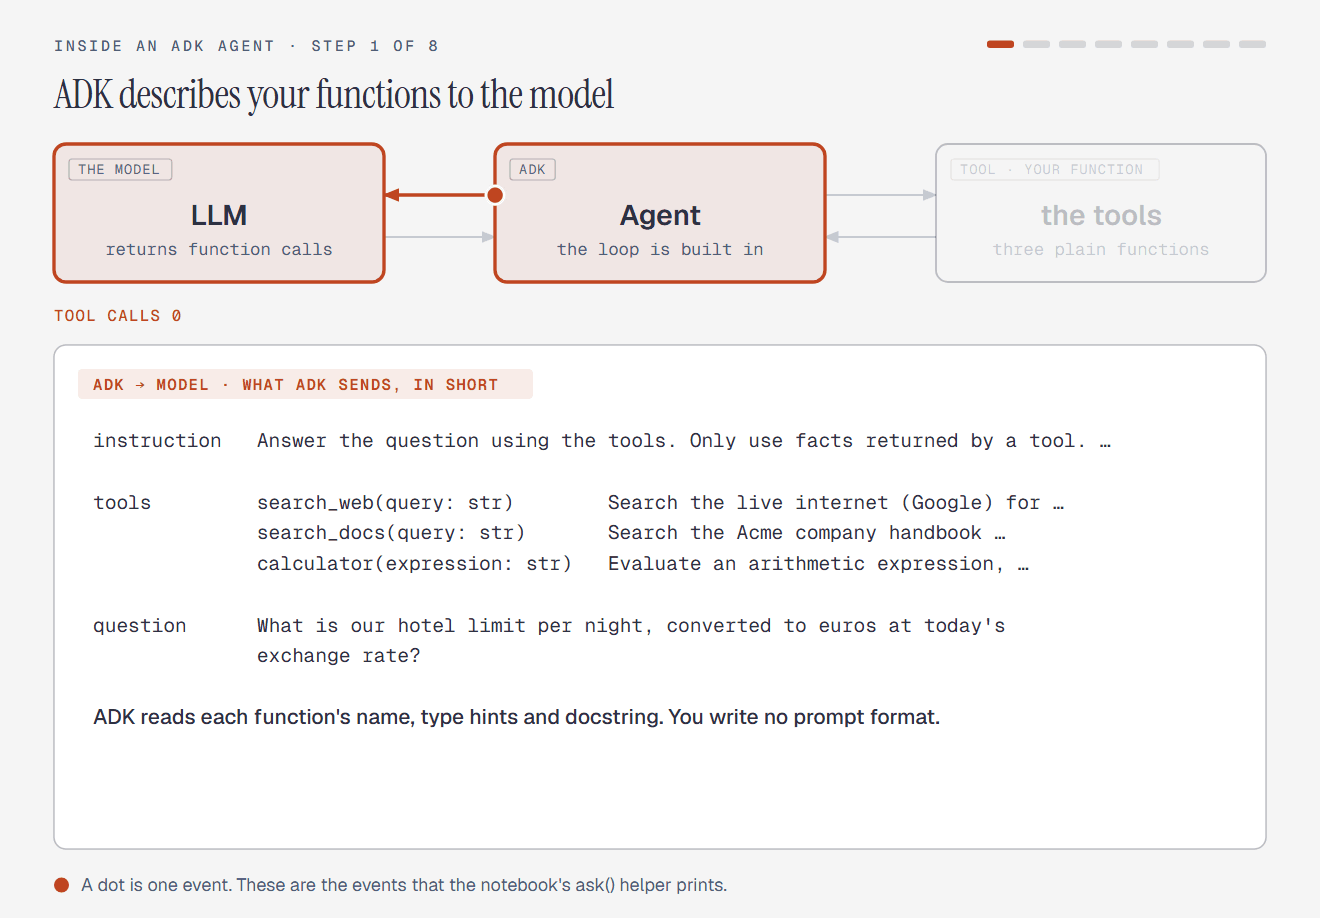

*Recorded from an earlier run. Values and wording change from run to run, so this will not match the output above exactly.*

## **1.4 Router: a `Workflow` with a route**

A `Workflow` is a graph: you fix the wiring, and the model only fills in the steps.

1. `classifier` (an LLM step) replies with one word: `web`, `docs` or `calc`.
2. `route` (plain Python) turns that word into a route with `Event(route=...)`.
3. The graph follows that route to **one** specialist. Each specialist has **one** tool.

The Router's limit is visible in the wiring: whichever branch is chosen, the other tools are simply not there.

### The nodes

The classifier, the three specialists and the `route` function.

In [14]:
# First node: an agent with no tools. It only names the branch.
classifier = Agent(
    name="classifier",
    model=ADK_MODEL,
    instruction="Pick the ONE best source for the question. Reply with exactly one word: "
                "web (live internet), docs (the Acme company handbook) or calc (arithmetic).",
)

# The branches: each one is an agent with a single tool.
def specialist(name, tool):
    """An agent that can use one tool only."""
    return Agent(
        name=name,
        model=ADK_MODEL,
        instruction=f"Call {tool.__name__} once, then answer in one or two plain sentences using only its result. "
                    "If the result is not enough, say what is missing.",
        tools=[tool],
    )

# Second node: plain Python, no model. node_input is what the classifier replied.
def route(node_input: str):
    """Turn the classifier's one-word reply into a route."""
    return Event(route=node_input.strip().lower())

### The graph

One row of `edges` wires everything: the question enters at `"START"`, goes to `classifier`, then to `route`, then to the one branch whose key matches the route.

In [15]:
# The graph: START -> classifier -> route -> the one branch whose key matches the route.
router_workflow = Workflow(
    name="router_workflow",
    edges=[
        ("START", classifier, route, {
            "web": specialist("web_agent", search_web),
            "docs": specialist("docs_agent", search_docs),
            "calc": specialist("calc_agent", calculator),
        }),
    ],
)

### Run it on the same question

Whichever branch the classifier picks, that branch has **one** tool. So it can find the hotel limit or the exchange rate, never both. At best it says what is missing. At worst it answers anyway, from whatever its one tool returned.

In [16]:
await ask(router_workflow, HARD)


 ROUTER_WORKFLOW  |  What is our hotel limit per night, converted to euros at today's exchange rate?

[classifier] web

Action: search_web({'query': '"hotel limit per night" travel policy'})
Observation: {'result': "Your company has a travel policy. But do your employees ...: Here's a quick test: Ask three employees, “What is our hotel limit per night in Nairobi?” If you get three different answers, your policy may ...\nHotel limit per night - Canada : r/postdoc: Hotel limit per night - Canada. Hi,.

[web_agent] The hotel limit is **€180 per night in capital cities** and **€130 elsewhere**; no exchange-rate conversion is needed because the limits are already in euros.


### Open the two traces in Phoenix

You just ran both agents on the hotel question, and Phoenix recorded each run as one **trace**. Run the cell below, then open the traces (newest at the top):

- **The Router:** `classifier`, then the one branch it picked, with one tool. Whichever branch it is, the other tools are not there.
- **ReAct:** `react_agent` calling `search_docs`, `search_web` and `calculator` in one loop.

Click any step to see exactly what went in and what came out. A score tells you *that* an answer is wrong. A trace tells you *why*.

In [ ]:
show_phoenix()  # Phoenix inside this notebook

### A different question takes a different branch

Same workflow, nothing rewired. Only the classifier's one-word reply changes.

In [17]:
await ask(router_workflow, "What is 18 percent of 2,450?")


 ROUTER_WORKFLOW  |  What is 18 percent of 2,450?

[classifier] calc

Action: calculator({'expression': '0.18 * 2450'})
Observation: {'result': '441.0'}

[calc_agent] 18 percent of 2,450 is 441.


**Behind the scenes.** A run on the hotel question where the classifier picked `docs`, as an animation: each step along the graph, with the exact text of the event it produced.

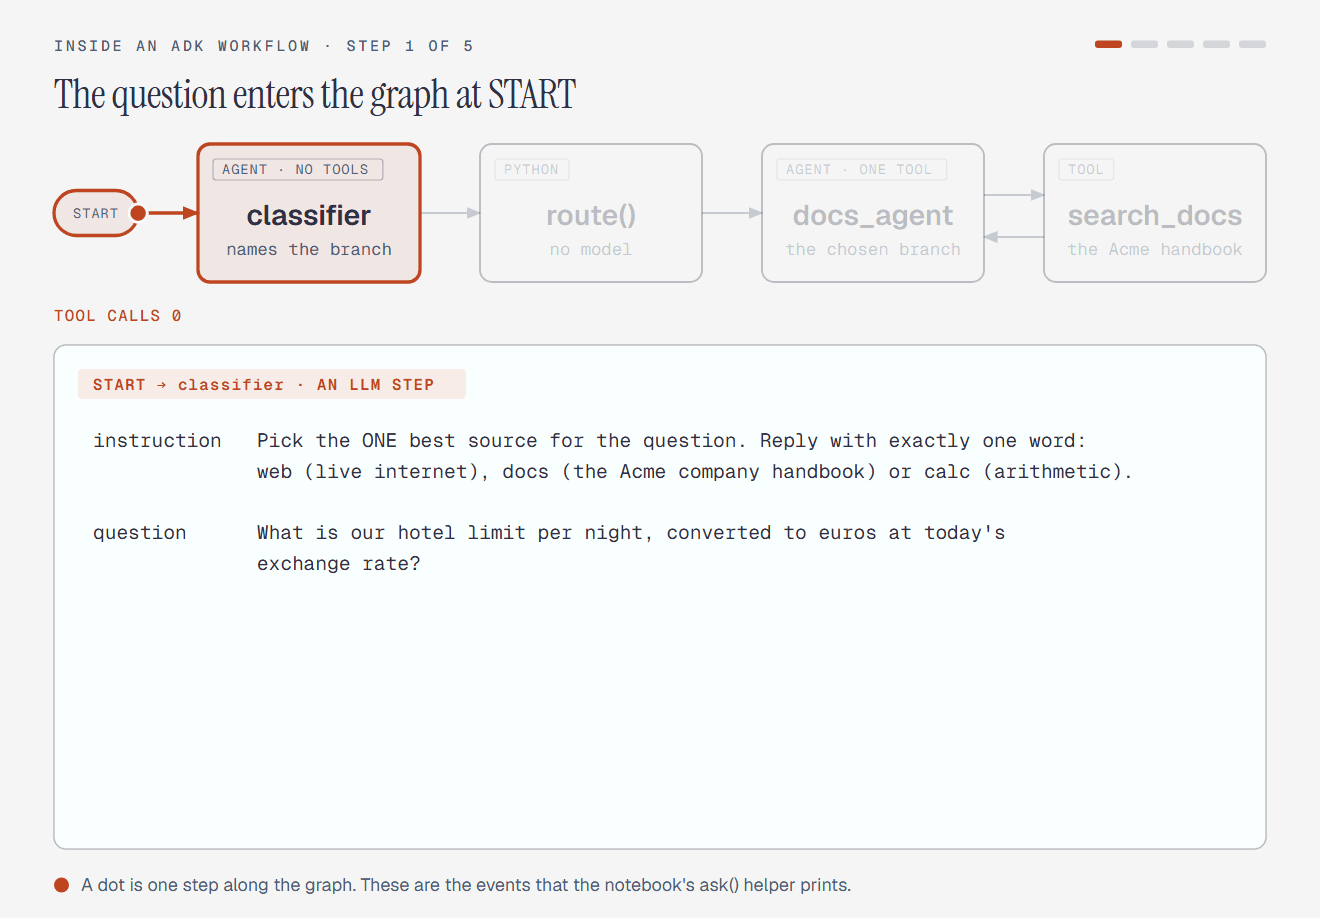

*Recorded from an earlier run. Values and wording change from run to run, so this will not match the output above exactly.*

## **1.5 Exercise: add your own tool**

Adding a tool takes two things:

1. Write a function with **type hints and a docstring**. The docstring tells the model **when** to use it.
2. Put the function in the agent's `tools=[...]` list.

There is no prompt to edit: ADK describes the new tool to the model for you.

Ideas: a word counter, a unit converter (km to miles), a dice roll, a lookup in your own small dictionary of facts.

Fill in the cell below, remove the `#` marks and run it. In the printed events, look for an `Action:` line with your tool's name: that is the proof the agent used it.

In [18]:
# 1. Write your tool. ADK reads the name, the type hints and the docstring.
#
# def my_tool(text: str) -> str:
#     """Say what the tool does and when the model should use it."""
#     return "..."

# 2. Build an agent that has it, and ask a question that needs it.
#
# my_agent = Agent(
#     name="my_agent",
#     model=ADK_MODEL,
#     instruction="Answer the question using the tools. Only use facts returned by a tool.",
#     tools=[search_web, search_docs, calculator, my_tool],
# )
# await ask(my_agent, "Ask something that needs your tool.")

<details>
<summary><b>Stuck? Click for a worked example</b> (a tool that counts words)</summary>

```python
def word_count(text: str) -> str:
    """Count the words in a piece of text."""
    return str(len(text.split()))

my_agent = Agent(
    name="my_agent",
    model=ADK_MODEL,
    instruction="Answer the question using the tools. Only use facts returned by a tool.",
    tools=[search_web, search_docs, calculator, word_count],
)
await ask(my_agent, "How many words are in this sentence: the quick brown fox jumps over the lazy dog")
```

</details>

## **1.6 Eval: Router vs ReAct on the same 12 questions**

One question is a demo. An **eval** is a set of questions with known answers, scored the same way for every agent, so you can compare them, on accuracy and on cost, and say which one does better on which **kind** of question.

This one has 12 questions in 4 kinds, three of each, from "one lookup" to "two documents, then arithmetic". Every answer is a number, so a few lines of code can check it.

**Before you run it:** which kinds do you expect the Router to get wrong?

### The questions

In [19]:
# Each row: the kind of question, the question, and the number a correct answer must contain.
EVAL = [
    ("One lookup",                 "How many paid vacation days do I get per year?", "25"),
    ("One lookup",                 "What is the laptop budget per employee?", "2000"),
    ("One lookup",                 "What is the daily meal limit when I travel?", "60"),
    ("One calculation",            "What is 18 percent of 2,450?", "441"),
    ("One calculation",            "What is 1,250 times 12?", "15000"),
    ("One calculation",            "What is 3,600 divided by 48?", "75"),
    ("One document + arithmetic",  "What is the most I can spend on hotels on a 4-night trip?", "720"),
    ("One document + arithmetic",  "What is the most I can spend on meals on a 5-day trip?", "300"),
    ("One document + arithmetic",  "Spread over the years a laptop is kept, what is the laptop budget per year?", "500"),
    ("Two documents + arithmetic", "How many hotel nights at the nightly limit does the laptop budget pay for?", "11"),
    ("Two documents + arithmetic", "What do hotels cost for all my paid vacation days, at the nightly limit?", "4500"),
    ("Two documents + arithmetic", "How many days of meals at the daily limit does the laptop budget pay for?", "33"),
]

### The scoring

- **`correct()`** checks one answer: does it contain the expected number?
- **`measure()`** runs one agent or workflow on one question without printing its events. It returns four things: the answer, the number of model replies, the tokens used and the seconds it took. ADK attaches a token count to every model reply, so there is nothing to count by hand.

In [20]:
import time

def correct(answer, expected):
    """True when the expected number appears in the answer. Commas are ignored, so 15,000 matches 15000."""

    # shortcut: a number match, fine when every answer is one number. Use a model as the judge for free-text answers.
    return re.search(rf"(?<![\d.]){expected}(?!\d)", str(answer).replace(",", "")) is not None

async def measure(node, question):
    """Run one agent or workflow on one question, quietly. Return its answer and what it cost."""

    # The same three lines as ask(): a runner, a session and the question as a message.
    runner = InMemoryRunner(node=node, app_name="demo")
    session = await runner.session_service.create_session(app_name="demo", user_id="student")
    message = types.Content(role="user", parts=[types.Part(text=question)])

    answer, calls, tokens, start = "", 0, 0, time.perf_counter()
    async for event in runner.run_async(user_id="student", session_id=session.id, new_message=message):

        # A reply from the model carries its token count. Tool results do not.
        if event.usage_metadata:
            calls += 1
            tokens += event.usage_metadata.total_token_count or 0

        # Keep the last text we see: that is the final answer.
        for part in (event.content and event.content.parts) or []:
            if part.text and not part.thought:
                answer = part.text.strip()

    return {"answer": answer, "calls": calls, "tokens": tokens, "seconds": time.perf_counter() - start}

# Small tests for the checker, with no model involved.
assert correct("That is 15,000 dollars.", "15000")
assert correct("About 11.11 nights.", "11")
assert not correct("The total is 1,441.", "441")  # 441 inside a longer number does not count
show("Checker tests", "All passed.")


 Checker tests
All passed.


### Run the eval

The Router workflow and the ReAct agent both answer every question. That is roughly 70 model calls, so this cell takes a while. None of the questions needs the web.

In [21]:
RESULTS = []  # one row per question
mark = lambda r: f"{'PASS' if r['ok'] else 'FAIL'}  {r['calls']} LLM calls  {r['tokens']:>6} tokens  {r['seconds']:5.1f}s"

show(f"Eval: {len(EVAL)} questions, both agents")
for number, (kind, question, expected) in enumerate(EVAL, 1):
    row = {"kind": kind}

    # Same question, same check: the Router workflow, then the ReAct agent.
    for name, node in (("router", router_workflow), ("react", react_agent)):
        row[name] = await measure(node, question)
        row[name]["ok"] = correct(row[name]["answer"], expected)
    RESULTS.append(row)

    print(f"\nQ{number} | {kind}\n    {question}")
    print(f"    Router  {mark(row['router'])}\n    ReAct   {mark(row['react'])}")


 Eval: 12 questions, both agents

Q1 | One lookup
    How many paid vacation days do I get per year?
    Router  pass  3 LLM calls     412 tokens    7.6s
    ReAct   pass  2 LLM calls     502 tokens    4.3s

Q2 | One lookup
    What is the laptop budget per employee?
    Router  pass  3 LLM calls     392 tokens    6.1s
    ReAct   pass  2 LLM calls     503 tokens    4.1s

Q3 | One lookup
    What is the daily meal limit when I travel?
    Router  pass  3 LLM calls     407 tokens    6.7s
    ReAct   pass  2 LLM calls     519 tokens    4.2s

Q4 | One calculation
    What is 18 percent of 2,450?
    Router  pass  3 LLM calls     355 tokens    5.6s
    ReAct   pass  2 LLM calls     483 tokens    4.0s

Q5 | One calculation
    What is 1,250 times 12?
    Router  pass  3 LLM calls     349 tokens    5.4s
    ReAct   pass  2 LLM calls     464 tokens    3.8s

Q6 | One calculation
    What is 3,600 divided by 48?
    Router  pass  3 LLM calls     351 tokens    5.4s
    ReAct   pass  2 LLM calls

### The score by kind of question

For each kind of question the code gives a verdict:

- The agent with **more correct answers** wins.
- If both score the same, the one that used **fewer tokens** is the better choice.
- If their tokens are within 10 percent of each other, there is **no clear winner**.

In [22]:
def average(rows, agent, field):
    """The average of one measurement (calls, tokens or seconds) for one agent."""
    return sum(row[agent][field] for row in rows) / len(rows)

def summary(rows, agent):
    """Like '3/3   2.0 calls     640 tokens    1.8s': correct answers, then the averages per question."""
    passed = sum(row[agent]["ok"] for row in rows)
    return (f"{f'{passed}/{len(rows)}':<5}  {average(rows, agent, 'calls'):4.1f} calls  "
            f"{average(rows, agent, 'tokens'):7.0f} tokens  {average(rows, agent, 'seconds'):5.1f}s")

def verdict(rows):
    """Which agent suits this kind of question: accuracy first, then cost."""

    # 1. More correct answers wins.
    router, react = (sum(row[agent]["ok"] for row in rows) for agent in ("router", "react"))
    if router != react:
        return f"{'ReAct' if react > router else 'Router'} wins: more correct answers"
    if router == 0:
        return "Neither: both got every question wrong"

    # 2. Same accuracy: the one that used fewer tokens, unless they are within 10 percent.
    r, a = average(rows, "router", "tokens"), average(rows, "react", "tokens")
    if abs(r - a) <= 0.1 * max(r, a):
        return "No clear winner: same accuracy, similar cost"
    return f"Same accuracy, {'Router' if r < a else 'ReAct'} is cheaper ({min(r, a) / max(r, a):.0%} of the tokens)"

show("Router vs ReAct by kind of question (averages per question)")

# One block per kind, in the order they appear in EVAL.
for kind in dict.fromkeys(row["kind"] for row in RESULTS):
    rows = [row for row in RESULTS if row["kind"] == kind]
    print(f"\n{kind}")
    print(f"    Router   {summary(rows, 'router')}")
    print(f"    ReAct    {summary(rows, 'react')}")
    print(f"    Verdict  {verdict(rows)}")

print(f"\n{'-' * 80}\nAll questions")
print(f"    Router   {summary(RESULTS, 'router')}")
print(f"    ReAct    {summary(RESULTS, 'react')}")


 Router vs ReAct by kind of question (averages per question)

One lookup
    Router   3/3     3.0 calls      404 tokens    6.8s
    ReAct    3/3     2.0 calls      508 tokens    4.2s
    Verdict  Same accuracy, Router is cheaper (79% of the tokens)

One calculation
    Router   3/3     3.0 calls      352 tokens    5.5s
    ReAct    3/3     2.0 calls      472 tokens    4.0s
    Verdict  Same accuracy, Router is cheaper (75% of the tokens)

One document + arithmetic
    Router   2/3     3.0 calls      462 tokens    6.6s
    ReAct    3/3     3.0 calls      880 tokens    7.0s
    Verdict  ReAct wins: more correct answers

Two documents + arithmetic
    Router   0/3     3.0 calls      560 tokens    7.4s
    ReAct    3/3     3.7 calls     1330 tokens    8.2s
    Verdict  ReAct wins: more correct answers

--------------------------------------------------------------------------------
All questions
    Router   8/12    3.0 calls      444 tokens    6.6s
    ReAct    12/12   2.7 calls      797

### How to read the result

- **Accuracy first, cost second.** A cheaper agent that gets the answer wrong has not saved anything.
- **Where both agents pass, compare the tokens.** The Router workflow is not free: it spends one model reply on the classifier before the chosen branch even starts.
- **Trust tokens more than seconds.** Seconds depend on the network and on how busy the model is, so a small difference in time means little.
- **Where only one agent passes, that kind of question needs something the other one lacks.** To see what, run the failed question with its events printed, for example `await ask(router_workflow, EVAL[9][1])`.
- **The check is simple and strict.** A correct answer that never states the number counts as a fail, so read a surprising fail before you trust it.
- **Twelve questions is a small set, and models vary from run to run.** Run the eval twice. A result that flips between runs is not a result yet.

## **1.7 What ADK does for you**

| The job | Who does it in ADK |
|---|---|
| Describing the tools to the model | `tools=[...]`: ADK reads each function's name, type hints and docstring |
| Asking for a tool | The model's built-in function calling. There is no text format to write or parse |
| The ReAct loop: run the tool, hand the result back, ask again | Built into `Agent` |
| Making sure a tool result is real | A tool result can only come from a real tool call |
| The Router: pick one branch and run it once | `Workflow` edges plus `Event(route=...)` |
| Seeing what happened | The event stream from `runner.run_async()` |

The ideas do not change: a Router decides once, a ReAct agent loops. The framework removes the plumbing.

# **Key Takeaways**

| | Router (`Workflow`) | ReAct (`Agent`) |
|---|---|---|
| How it works | One decision, then one branch | A loop: act, observe, decide again |
| Tools it can use | Only the tool of the chosen branch | Any tool, as many times as needed |
| Cost and speed | Fixed and predictable | Varies with the question |
| Questions that need more than one tool call | Cannot answer them. At best it says what is missing | Can answer them |
| What can go wrong | It picks the wrong branch, and there is no second try | It can take more steps than you expect |
| Good fit | Many questions of a few clearly separate kinds | Open questions, where the next step depends on the last result |

**Rule of thumb:** start with a Router. Move to ReAct when you find questions it cannot answer in one step.

**And a tool is just a function with a good description.** ADK built everything else from its name, type hints and docstring.

**Where to go next**

- Try a question of your own that needs two tools, and predict which branch the Router will take before you run it.